# 15. Clustering: Finding Structure Without Labels

Every chapter so far has assumed you have labels: a diagnosis, a credit outcome, a class.
Clustering starts without them. You have features and the goal is to discover groups that the
data itself suggests — without being told what to look for.

That changes almost everything about the workflow. There is no `y` to pass to `fit`. There is
no accuracy score to read off at the end. Instead, you choose an algorithm that encodes an
assumption about what a cluster *is*, run it, and then use indirect evidence to judge whether
the result makes sense.

**You will learn:**

- how to generate and visualise synthetic cluster data
- what K-Means, Agglomerative, DBSCAN, and Gaussian Mixture Models each assume
- three internal evaluation metrics you can use without ground truth
- one external metric for when you do have labels to compare against
- how to use a silhouette sweep to guide the choice of k — and why it is not always right

## 15.1 Generating synthetic data

TuiML ships two clustering data generators. `Blobs` creates well-separated Gaussian blobs where
every algorithm should succeed. `Moons` creates two crescent shapes that break K-Means, which
is where the interesting comparison happens.

We load both here and keep them available for the sections that follow.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tuiml.datasets.generators import Blobs, Moons

blobs_data = Blobs(n_samples=400, n_features=2, n_clusters=3, random_state=42).generate()
X_blobs, y_true = blobs_data.X, blobs_data.y

moons_data = Moons(n_samples=400, noise=0.05, random_state=42).generate()
X_moons, y_moons = moons_data.X, moons_data.y

print(f"Blobs:  X={X_blobs.shape}  true clusters: {len(np.unique(y_true))}")
print(f"Moons:  X={X_moons.shape}  true clusters: {len(np.unique(y_moons))}")

Blobs:  X=(400, 2)  true clusters: 3
Moons:  X=(400, 2)  true clusters: 2


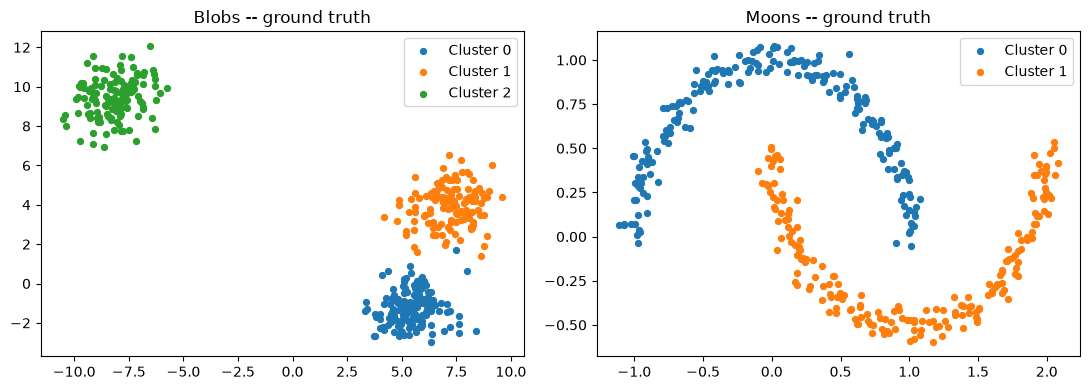

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for k in np.unique(y_true):
    mask = y_true == k
    axes[0].scatter(X_blobs[mask, 0], X_blobs[mask, 1], s=18, label=f"Cluster {k}")
axes[0].set_title("Blobs -- ground truth")
axes[0].legend()

for k in np.unique(y_moons):
    mask = y_moons == k
    axes[1].scatter(X_moons[mask, 0], X_moons[mask, 1], s=18, label=f"Cluster {k}")
axes[1].set_title("Moons -- ground truth")
axes[1].legend()

plt.tight_layout()
plt.show()

## 15.2 K-Means clustering

`KMeansClusterer` partitions the data into `n_clusters` groups by iteratively moving centroids
to minimise total within-cluster squared distance. It is fast and works well when clusters are
convex and roughly equally sized.

Every TuiML clusterer has the same two methods: `.fit(X)` learns the cluster structure; `.predict(X)`
assigns each row to a cluster. There is no `y` argument anywhere.

We evaluate the result with four metrics. Three of them — silhouette, Davies-Bouldin, and
Calinski-Harabasz — need only X and the predicted labels. They are the ones you reach for in a
real problem where ground truth does not exist. The fourth — Adjusted Rand Index — compares to
the true labels and is included here because we know them.

In [3]:
from tuiml.algorithms.clustering import KMeansClusterer
from tuiml.evaluation import silhouette_score, adjusted_rand_score
from tuiml.evaluation.metrics import davies_bouldin_score, calinski_harabasz_score

km = KMeansClusterer(n_clusters=3, random_state=42)
km.fit(X_blobs)
km_labels = km.predict(X_blobs)

sil = silhouette_score(X_blobs, km_labels)
dbi = davies_bouldin_score(X_blobs, km_labels)
chi = calinski_harabasz_score(X_blobs, km_labels)
ari = adjusted_rand_score(y_true, km_labels)

print("K-Means (k=3) on Blobs")
print(f"  Silhouette score        : {sil:.3f}   (range -1 to 1; higher is better)")
print(f"  Davies-Bouldin index    : {dbi:.3f}   (lower is better)")
print(f"  Calinski-Harabasz index : {chi:.0f} (higher is better)")
print()
print(f"  Adjusted Rand Index (vs ground truth): {ari:.3f}")

K-Means (k=3) on Blobs
  Silhouette score        : 0.754   (range -1 to 1; higher is better)
  Davies-Bouldin index    : 0.345   (lower is better)
  Calinski-Harabasz index : 6879 (higher is better)

  Adjusted Rand Index (vs ground truth): 0.992


An **ARI of 0.992** means K-Means recovered the ground truth almost perfectly. In a real problem
you would not have `y_true`, so the three internal metrics are what you would report. All three
agree: silhouette near 0.75 indicates well-separated clusters, DBI near 0.35 is low (good), and a
CHI of 6879 is high relative to what you would see with random labels.

Use internal metrics as *relative* comparisons between configurations, not as absolute quality
certificates. A silhouette of 0.75 in one problem is not directly comparable to 0.75 in another.

## 15.3 Choosing the number of clusters

In practice you rarely know k. One common heuristic: fit K-Means for a range of k values and
plot the silhouette score at each. The k where it drops off sharpest is a candidate.

This is a heuristic, not a theorem. The sweep below shows a real failure case: the silhouette
score peaks at k=2, not k=3, even though the data was generated with three clusters. Understanding
why helps you avoid over-trusting the method.

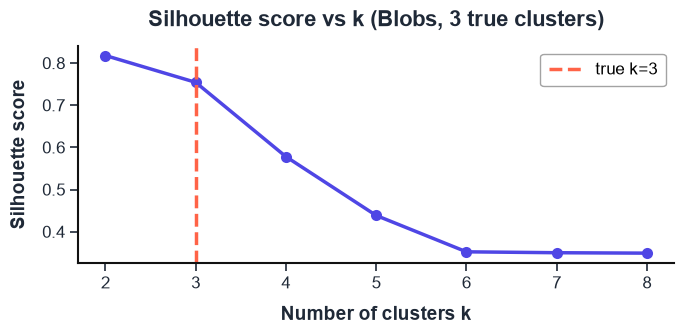

k with highest silhouette : 2   (true k is 3)


In [4]:
ks = range(2, 9)
sil_scores = []

for k in ks:
    km_k = KMeansClusterer(n_clusters=k, random_state=42)
    km_k.fit(X_blobs)
    labels_k = km_k.predict(X_blobs)
    sil_scores.append(silhouette_score(X_blobs, labels_k))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(list(ks), sil_scores, marker="o", color="#4f46e5")
ax.axvline(3, color="tomato", linestyle="--", label="true k=3")
ax.set_xlabel("Number of clusters k")
ax.set_ylabel("Silhouette score")
ax.set_title("Silhouette score vs k (Blobs, 3 true clusters)")
ax.legend()
plt.tight_layout()
plt.show()

best_k = list(ks)[int(np.argmax(sil_scores))]
print(f"k with highest silhouette : {best_k}   (true k is 3)")

The sweep picked k=2. This is not a bug — it is an important lesson. K-Means at k=2 merges two
of the three blobs into one large cluster. That larger merged cluster still looks reasonably
cohesive by the silhouette measure, so the score is higher than at k=3.

The silhouette sweep is one data point, not a definitive answer. Domain knowledge, visualisation,
and the downstream task should inform the final choice. When you have no ground truth at all,
plot the cluster assignments at several candidate k values and ask whether the groupings make
sense for your problem.

## 15.4 Agglomerative clustering

`AgglomerativeClusterer` takes a different approach: it starts with every point as its own cluster
and merges the closest pair at each step. The `linkage` parameter controls what "closest" means
between two clusters. `ward` linkage — which minimises total within-cluster variance after a merge
— is usually the best starting point for compact, similarly-sized clusters.

Unlike K-Means, agglomerative clustering does not use random initialisation, so it is fully
deterministic given the data.

In [5]:
from tuiml.algorithms.clustering import AgglomerativeClusterer

agglo = AgglomerativeClusterer(n_clusters=3, linkage="ward")
agglo.fit(X_blobs)
agglo_labels = agglo.predict(X_blobs)

ari_a = adjusted_rand_score(y_true, agglo_labels)
sil_a = silhouette_score(X_blobs, agglo_labels)
print(f"Agglomerative (ward, k=3)  ARI: {ari_a:.3f}   Silhouette: {sil_a:.3f}")

Agglomerative (ward, k=3)  ARI: 0.992   Silhouette: 0.754


Agglomerative with ward linkage matches K-Means almost exactly on this well-behaved dataset —
both score ARI 0.992. The difference becomes visible on more complex shapes or when clusters
have very different densities.

The practical advantage of agglomerative clustering is that it does not depend on random
initialisation and it implicitly computes a hierarchy: you can cut the dendrogram at a different
level to get a different number of clusters without re-running the fit.

## 15.5 DBSCAN -- when clusters are not convex

Both K-Means and Agglomerative assume clusters are roughly spherical. The Moons dataset breaks
that assumption. DBSCAN (`DBSCANClusterer`) takes a completely different approach: it grows
clusters from dense regions, following any shape, and labels sparse points as noise (label `-1`).

Two parameters control what "dense" means:
- `eps`: the radius within which a point looks for neighbours
- `min_samples`: the minimum number of neighbours needed for a point to be a core point

DBSCAN does not ask you to specify k in advance.

In [6]:
from tuiml.algorithms.clustering import DBSCANClusterer

# K-Means on Moons -- struggles because clusters are not convex
km_m = KMeansClusterer(n_clusters=2, random_state=42)
km_m.fit(X_moons)
km_m_labels = km_m.predict(X_moons)
print(f"K-Means on Moons   ARI: {adjusted_rand_score(y_moons, km_m_labels):.3f}   "
      f"clusters found: {len(np.unique(km_m_labels))}")

# DBSCAN on Moons -- follows the curved shapes naturally
db = DBSCANClusterer(eps=0.2, min_samples=5)
db.fit(X_moons)
db_labels = db.predict(X_moons)
n_clusters_found = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = int((db_labels == -1).sum())
print(f"DBSCAN  on Moons   ARI: {adjusted_rand_score(y_moons, db_labels):.3f}   "
      f"clusters found: {n_clusters_found}   noise points: {n_noise}")

K-Means on Moons   ARI: 0.253   clusters found: 2
DBSCAN  on Moons   ARI: 1.000   clusters found: 2   noise points: 0


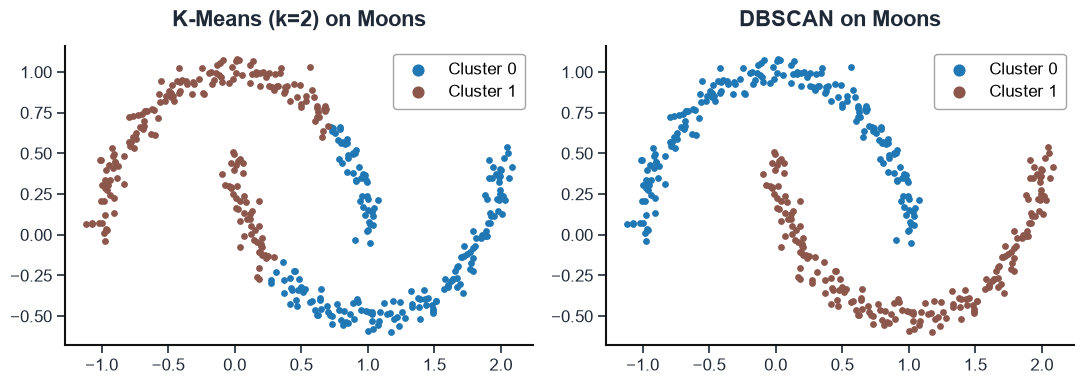

In [7]:
import matplotlib

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, labels, title in zip(
    axes,
    [km_m_labels, db_labels],
    ["K-Means (k=2) on Moons", "DBSCAN on Moons"],
):
    unique = sorted(set(labels))
    cmap = matplotlib.colormaps["tab10"]
    for i, c in enumerate(unique):
        mask = labels == c
        colour = "grey" if c == -1 else cmap(i / max(len(unique), 1))
        label = "noise" if c == -1 else f"Cluster {c}"
        ax.scatter(X_moons[mask, 0], X_moons[mask, 1], s=15, color=colour, label=label)
    ax.set_title(title)
    ax.legend(markerscale=2)

plt.tight_layout()
plt.show()

K-Means cuts the data with a straight boundary. Because the crescents overlap in the horizontal
direction, that straight cut slices each crescent in half and assigns each half to the wrong
cluster. The ARI of 0.253 — barely better than random — reflects this failure.

DBSCAN does not draw boundaries at all. It labels a point as belonging to the same cluster as
its close neighbours, regardless of global shape. With `eps=0.2` and `min_samples=5`, it
traces each crescent perfectly and finds zero noise points.

The cost of this flexibility is that DBSCAN requires you to set `eps` and `min_samples`
carefully. Small changes to `eps` can merge two valid clusters or split one real cluster into
many fragments. A good starting point is to look at the distribution of distances to the k-th
nearest neighbour and pick the value where that curve bends sharply.

## 15.6 Gaussian Mixture Models

`GaussianMixtureClusterer` fits a mixture of multivariate Gaussians using the
expectation-maximisation algorithm. Unlike K-Means, it assigns *soft* cluster memberships:
each point gets a probability of belonging to each component, and the hard label is the
argmax of those probabilities.

This makes it more expressive than K-Means on ellipsoidal clusters and gives you a proper
probabilistic model you can use for density estimation or anomaly detection.

In [8]:
from tuiml.algorithms.clustering import GaussianMixtureClusterer

gmm = GaussianMixtureClusterer(n_components=3, random_state=42)
gmm.fit(X_blobs)
gmm_labels = gmm.predict(X_blobs)

ari_g = adjusted_rand_score(y_true, gmm_labels)
sil_g = silhouette_score(X_blobs, gmm_labels)
print(f"GMM (3 components) on Blobs   ARI: {ari_g:.3f}   Silhouette: {sil_g:.3f}")

GMM (3 components) on Blobs   ARI: 0.985   Silhouette: 0.754


GMM scores ARI 0.985 on the same Blobs data — slightly below K-Means (0.992) because the EM
optimisation found a locally suboptimal solution. On ellipsoidal clusters that are not
spherical, GMM typically outperforms K-Means.

Note the parameter name: `n_components`, not `n_clusters`. That naming reflects that GMM is a
generative model. Each component is a Gaussian distribution, and a cluster is the set of
points that the component explains with highest probability.

## 15.7 Comparing the four algorithms

A summary of performance and the assumptions each algorithm makes:

In [9]:
print(f"{'Algorithm':24s} {'ARI on Blobs':14s} {'ARI on Moons':14s} {'Needs k?':10s} {'Handles noise?'}")
print("-" * 78)
rows = [
    ("K-Means",          f"{adjusted_rand_score(y_true,   km_labels):.3f}",
                         f"{adjusted_rand_score(y_moons,  km_m_labels):.3f}",   "yes", "no"),
    ("Agglomerative",    f"{adjusted_rand_score(y_true,   agglo_labels):.3f}",
                         "--",                                                   "yes", "no"),
    ("DBSCAN",           "--",
                         f"{adjusted_rand_score(y_moons,  db_labels):.3f}",     "no",  "yes"),
    ("Gaussian Mixture", f"{adjusted_rand_score(y_true,   gmm_labels):.3f}",
                         "--",                                                   "yes", "no"),
]
for name, blob_ari, moon_ari, needs_k, noise in rows:
    print(f"{name:24s} {blob_ari:14s} {moon_ari:14s} {needs_k:10s} {noise}")

Algorithm                ARI on Blobs   ARI on Moons   Needs k?   Handles noise?
------------------------------------------------------------------------------
K-Means                  0.992          0.253          yes        no
Agglomerative            0.992          --             yes        no
DBSCAN                   --             1.000          no         yes
Gaussian Mixture         0.985          --             yes        no


## Recap

- **Clustering is unsupervised**: there is no `y` in `fit`. The algorithm discovers
  structure; you decide whether that structure is useful.
- **K-Means** (`KMeansClusterer`) is fast and accurate on compact, convex, similarly-sized
  blobs. It requires you to specify k and assumes Euclidean distance.
- **Agglomerative** (`AgglomerativeClusterer`) builds a hierarchy bottom-up. Ward linkage
  minimises within-cluster variance and is the best default. Fully deterministic.
- **DBSCAN** (`DBSCANClusterer`) finds clusters of any shape and flags outliers as noise.
  It does not require k, but is sensitive to `eps` and `min_samples`.
- **Gaussian Mixture** (`GaussianMixtureClusterer`) assigns soft probabilities and models
  ellipsoidal clusters. Use `n_components`, not `n_clusters`.
- **When you have ground truth**, use `adjusted_rand_score`. When you do not, use
  `silhouette_score`, `davies_bouldin_score`, and `calinski_harabasz_score` — and treat them
  as relative comparisons between configurations, not absolute quality certificates.
- **Silhouette sweeps help but are not oracles.** On this dataset the sweep peaks at k=2
  even though the data was generated with k=3. Always combine heuristics with visualisation
  and domain knowledge.

**Next:** chapter 16 covers streaming and online learning — updating a model one sample at a
time as new data arrives, without retraining from scratch.